In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving customer_churn_sample.csv to customer_churn_sample.csv


In [3]:
df = pd.read_csv("customer_churn_sample.csv")

df.head()

,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


In [5]:
df.shape

(15, 11)

In [6]:
df.columns


Index(['CustomerID', 'Gender', 'Age', 'TenureMonths', 'SubscriptionType',
       'MonthlyCharges', 'TotalCharges', 'ContractType', 'SupportTickets',
       'PaymentMethod', 'Churn'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     object 
 1   Gender            15 non-null     object 
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     object 
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     object 
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     object 
 10  Churn             15 non-null     object 
dtypes: float64(2), int64(3), object(6)
memory usage: 1.4+ KB


In [8]:
df.describe()

,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,39.066667,18.800000,84.656667,2088.478667,2.533333
std,11.392144,14.333776,42.739521,2407.365767,1.922300
min,23.000000,2.000000,49.990000,99.980000,0.000000
25%,30.000000,7.000000,49.990000,449.910000,1.000000
50%,38.000000,15.000000,79.990000,1099.780000,2.000000
75%,47.000000,27.000000,114.990000,3209.730000,4.000000
max,60.000000,48.000000,149.990000,7199.520000,6.000000


In [9]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
TenureMonths,0
SubscriptionType,0
MonthlyCharges,0
TotalCharges,0
ContractType,0
SupportTickets,0
PaymentMethod,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["CustomerID"].duplicated().sum()

np.int64(0)

In [12]:
clean_df = df.copy()

print("Original shape:", df.shape)
print("Cleaned shape:", clean_df.shape)

Original shape: (15, 11)
Cleaned shape: (15, 11)


In [13]:
text_columns = clean_df.select_dtypes(
    include="object"
).columns

for col in text_columns:
    clean_df[col] = clean_df[col].str.strip()

print("Text values standardized successfully!")

Text values standardized successfully!


In [14]:
print("Negative Age:", (clean_df["Age"] < 0).sum())

print("Negative Tenure:",
      (clean_df["TenureMonths"] < 0).sum())

print("Negative Monthly Charges:",
      (clean_df["MonthlyCharges"] < 0).sum())

print("Negative Total Charges:",
      (clean_df["TotalCharges"] < 0).sum())

print("Negative Support Tickets:",
      (clean_df["SupportTickets"] < 0).sum())

Negative Age: 0
Negative Tenure: 0
Negative Monthly Charges: 0
Negative Total Charges: 0
Negative Support Tickets: 0


In [15]:
print("Gender:")
print(clean_df["Gender"].unique())

print("\nSubscription Type:")
print(clean_df["SubscriptionType"].unique())

print("\nContract Type:")
print(clean_df["ContractType"].unique())

print("\nChurn:")
print(clean_df["Churn"].unique())

Gender:
['Female' 'Male']

Subscription Type:
['Basic' 'Pro' 'Enterprise']

Contract Type:
['Month-to-Month' 'One Year' 'Two Year']

Churn:
['Yes' 'No']


In [16]:
expected_charges = (
    clean_df["TenureMonths"] *
    clean_df["MonthlyCharges"]
)

check = np.isclose(
    clean_df["TotalCharges"],
    expected_charges
)

print("Consistent records:", check.sum())
print("Inconsistent records:", (~check).sum())

Consistent records: 15
Inconsistent records: 0


In [17]:
cleaning_log = pd.DataFrame({
    "Quality Check": [
        "Missing Values",
        "Duplicate Rows",
        "Duplicate Customer IDs",
        "Negative Values",
        "TotalCharges Consistency",
        "Text Standardization"
    ],

    "Action Taken": [
        "Checked all columns",
        "Checked duplicate records",
        "Checked unique identifiers",
        "Validated numerical columns",
        "Compared calculated charges",
        "Removed leading and trailing spaces"
    ],

    "Result": [
        "No missing values",
        "No duplicates",
        "No duplicate IDs",
        "No negative values",
        "All records consistent",
        "Standardization applied"
    ]
})

cleaning_log

,Quality Check,Action Taken,Result
0,Missing Values,Checked all columns,No missing values
1,Duplicate Rows,Checked duplicate records,No duplicates
2,Duplicate Customer IDs,Checked unique identifiers,No duplicate IDs
3,Negative Values,Validated numerical columns,No negative values
4,TotalCharges Consistency,Compared calculated charges,All records consistent
5,Text Standardization,Removed leading and trailing spaces,Standardization applied


In [18]:
print("Final Dataset Shape:", clean_df.shape)

print("\nMissing Values:")
print(clean_df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(clean_df.duplicated().sum())

print("\nDataset Preview:")
display(clean_df.head())

Final Dataset Shape: (15, 11)

Missing Values:
0

Duplicate Rows:
0

Dataset Preview:


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


In [19]:
clean_df.to_csv(
    "cleaned_customer_churn.csv",
    index=False
)

files.download("cleaned_customer_churn.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
clean_df.describe()

,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,39.066667,18.800000,84.656667,2088.478667,2.533333
std,11.392144,14.333776,42.739521,2407.365767,1.922300
min,23.000000,2.000000,49.990000,99.980000,0.000000
25%,30.000000,7.000000,49.990000,449.910000,1.000000
50%,38.000000,15.000000,79.990000,1099.780000,2.000000
75%,47.000000,27.000000,114.990000,3209.730000,4.000000
max,60.000000,48.000000,149.990000,7199.520000,6.000000


In [21]:
print("Average Age:", clean_df["Age"].mean())

print("Average Tenure:",
      clean_df["TenureMonths"].mean())

print("Average Monthly Charges:",
      clean_df["MonthlyCharges"].mean())

print("Average Support Tickets:",
      clean_df["SupportTickets"].mean())

Average Age: 39.06666666666667
Average Tenure: 18.8
Average Monthly Charges: 84.65666666666668
Average Support Tickets: 2.533333333333333


In [22]:
print("Mean Age:", clean_df["Age"].mean())
print("Median Age:", clean_df["Age"].median())
print("Mode Age:", clean_df["Age"].mode()[0])

Mean Age: 39.06666666666667
Median Age: 38.0
Mode Age: 23


In [23]:
print(clean_df["Churn"].value_counts())

Churn
No     8
Yes    7
Name: count, dtype: int64


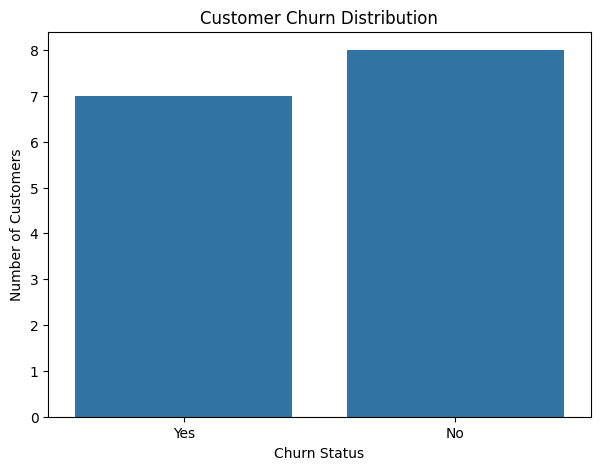

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(data=clean_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

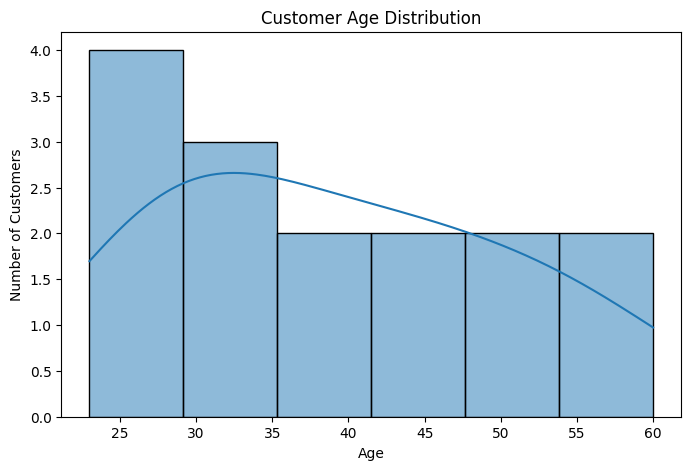

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=clean_df,
    x="Age",
    bins=6,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

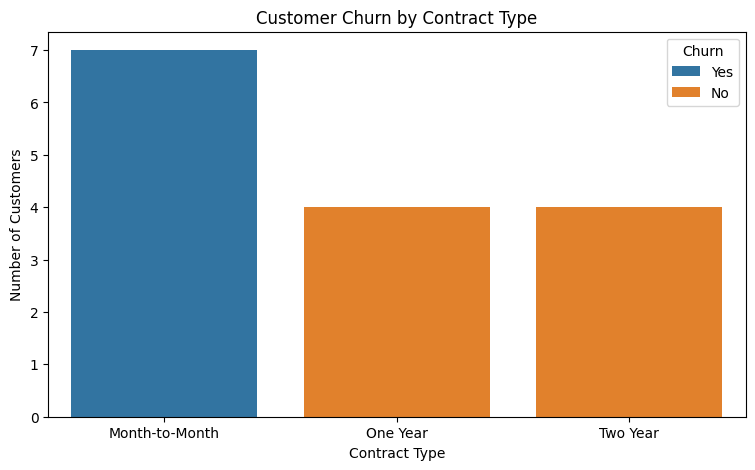

In [26]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=clean_df,
    x="ContractType",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

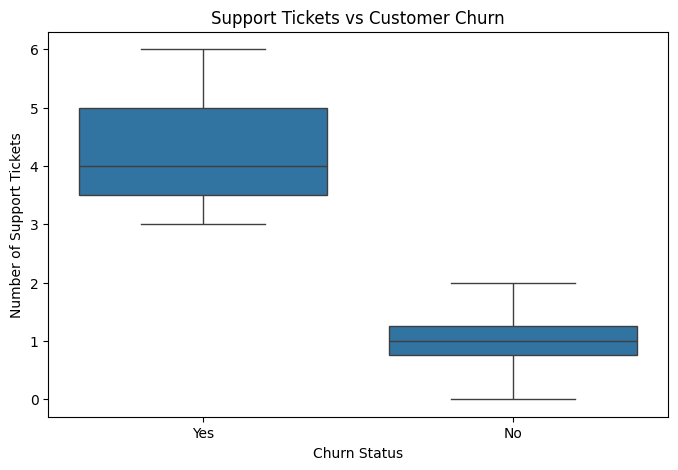

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="Churn",
    y="SupportTickets"
)

plt.title("Support Tickets vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Support Tickets")

plt.show()

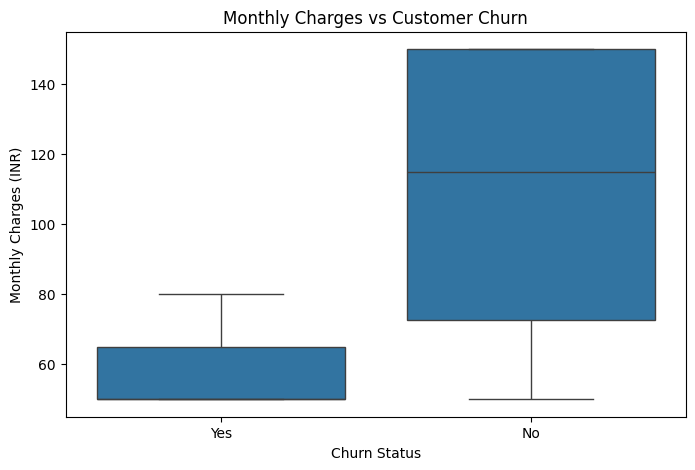

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges (INR)")

plt.show()

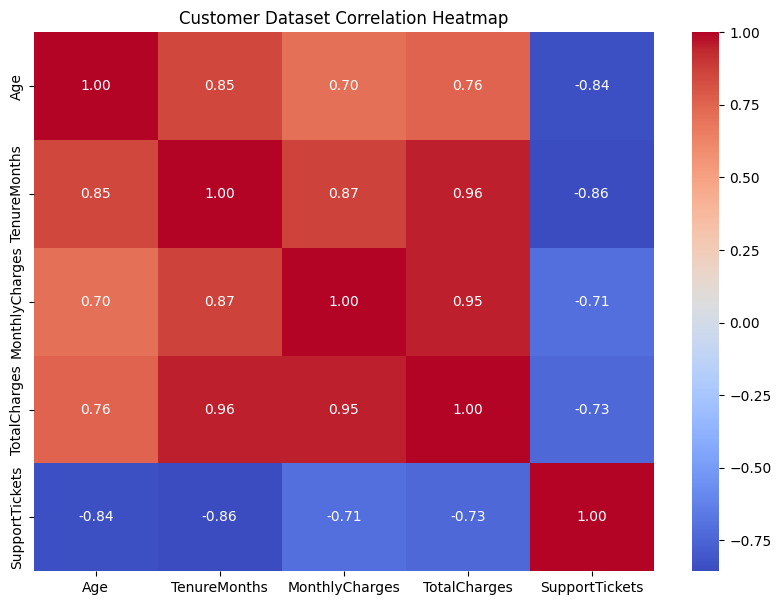

In [29]:
plt.figure(figsize=(10, 7))

correlation = clean_df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Dataset Correlation Heatmap")

plt.show()

In [30]:
churn_summary = clean_df.groupby("Churn").agg(
    Total_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Tenure=("TenureMonths", "mean"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Average_Support_Tickets=("SupportTickets", "mean")
)

display(churn_summary.round(2))

,Total_Customers,Average_Age,Average_Tenure,Average_Monthly_Charges,Average_Support_Tickets
Churn,,,,,
No,8,46.62,29.12,107.49,1.00
Yes,7,30.43,7.00,58.56,4.29


In [31]:
print("DATA QUALITY SUMMARY")
print("--------------------")

print("Total Records:", len(clean_df))
print("Total Columns:", len(clean_df.columns))

print("Missing Values:",
      clean_df.isnull().sum().sum())

print("Duplicate Rows:",
      clean_df.duplicated().sum())

print("Duplicate Customer IDs:",
      clean_df["CustomerID"].duplicated().sum())

print("Negative Age:",
      (clean_df["Age"] < 0).sum())

print("Negative Tenure:",
      (clean_df["TenureMonths"] < 0).sum())

print("Negative Charges:",
      (clean_df["MonthlyCharges"] < 0).sum())

print("Negative Support Tickets:",
      (clean_df["SupportTickets"] < 0).sum())

DATA QUALITY SUMMARY
--------------------
Total Records: 15
Total Columns: 11
Missing Values: 0
Duplicate Rows: 0
Duplicate Customer IDs: 0
Negative Age: 0
Negative Tenure: 0
Negative Charges: 0
Negative Support Tickets: 0


In [33]:
data_dictionary = pd.DataFrame({
    "Column": [
        "CustomerID",
        "Gender",
        "Age",
        "TenureMonths",
        "SubscriptionType",
        "MonthlyCharges",
        "TotalCharges",
        "ContractType",
        "SupportTickets",
        "PaymentMethod",
        "Churn"
    ],

    "Description": [
        "Unique customer identifier",
        "Customer gender",
        "Customer age in years",
        "Months since signup",
        "Subscription plan",
        "Monthly subscription amount in INR",
        "Total amount charged in INR",
        "Customer contract duration",
        "Support tickets in the previous period",
        "Customer payment method",
        "Whether the customer left"
    ]
})

display(data_dictionary)

,Column,Description
0,CustomerID,Unique customer identifier
1,Gender,Customer gender
2,Age,Customer age in years
3,TenureMonths,Months since signup
4,SubscriptionType,Subscription plan
5,MonthlyCharges,Monthly subscription amount in INR
6,TotalCharges,Total amount charged in INR
7,ContractType,Customer contract duration
8,SupportTickets,Support tickets in the previous period
9,PaymentMethod,Customer payment method


In [34]:
print("""
CUSTOMER CHURN ANALYSIS - FINAL REPORT

1. DATASET OVERVIEW
The dataset contains 15 customer records
and 11 columns.

2. DATA QUALITY
No missing values or duplicate records
were identified.
All 15 customer records passed the
TotalCharges consistency check.

3. CUSTOMER CHURN
8 customers were retained.
7 customers churned.

4. KEY FINDINGS
Month-to-Month contracts had 7 churned
customers.

Retained customers had an average of
1 support ticket.

Churned customers had an average of
4.29 support tickets.

5. CONCLUSION
The sample indicates an association
between customer churn, contract type,
and support-ticket volume.

6. LIMITATIONS
The dataset contains only 15 synthetic
customer records. Findings should not
be generalized to real customers.
""")


CUSTOMER CHURN ANALYSIS - FINAL REPORT

1. DATASET OVERVIEW
The dataset contains 15 customer records
and 11 columns.

2. DATA QUALITY
No missing values or duplicate records
were identified.
All 15 customer records passed the
TotalCharges consistency check.

3. CUSTOMER CHURN
8 customers were retained.
7 customers churned.

4. KEY FINDINGS
Month-to-Month contracts had 7 churned
customers.

Retained customers had an average of
1 support ticket.

Churned customers had an average of
4.29 support tickets.

5. CONCLUSION
The sample indicates an association
between customer churn, contract type,
and support-ticket volume.

6. LIMITATIONS
The dataset contains only 15 synthetic
customer records. Findings should not
be generalized to real customers.

